<a href="https://colab.research.google.com/github/vasalanavya/Nassau_Candu_KPI-Dashboard/blob/main/Nassau_Candy_Distributor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Product Line Profitability & Margin Performance Analysis For Nassau Candy Distributor**

# uploading and understanding the data

In [2]:
# Load "Numpy" and "Pandas" for manipulating numbers and Data Frame
#Load "matplotlib.pyplot" and "seaborn" for data visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# read in the "Nassau Candy Distributor.csv" file as a pandas DataFrame
data=pd.read_csv('/content/Nassau Candy Distributor.csv')

In [ ]:
#Take a brief look at the data
data.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
5,6,US-2021-167199-CHO-SCR-58000,06-01-2024,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,32.40,9,22.50,9.90
6,7,US-2021-167199-CHO-TRI-54000,06-01-2024,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
7,8,US-2021-106054-CHO-MIL-31000,06-01-2024,30-06-2026,First Class,106054,United States,Athens,Georgia,30605,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
8,9,US-2021-167199-CHO-NUT-13000,06-01-2024,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
9,10,US-2021-167199-CHO-MIL-31000,06-01-2024,03-07-2026,Standard Class,167199,United States,Henderson,Kentucky,42420,Chocolate,Gulf,CHO-MIL-31000,Wonka Bar - Milk Chocolate,13.00,4,8.44,4.56


In [ ]:
#get the dimension of the dataframe
data.shape
#get the row names of the dataframe
data.index
#get the column names of the dataframe
data.columns
#look at the basic information about the dataframe
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

# **Problem statement**


# *  which product line deliver the highest gross margin
# *   Whether high-sales product are actually profitable


# *   How profitability varies across product divisions
# *   Which Product represents margin risk









In [ ]:
#clean and validate the data
print(data.isnull().sum())
#check duplicate rows
print("Duplicate rows:",data.duplicated().sum())
#check data type
print(data.dtypes)
#check basic statistics
display(data.describe())

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64
Duplicate rows: 0
Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID         int64
Country/Region     object
City               object
State/Province     object
Postal Code        object
Division           object
Region             object
Product ID         object
Product Name       object
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object


,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


In [ ]:
#validating sales and cost
#converting sales and cost into numeric values
data['Sales']=pd.to_numeric(data['Sales'],errors='coerce')
data['Cost']=pd.to_numeric(data['Cost'],errors='coerce')
#counting invalid or missing values
print("Missing values:",data['Sales'].isna().sum())
print("Missing values:",data['Cost'].isna().sum())
#count negative sales and cost
print("Nagitive sales:",(data['Sales']<0).sum())
print("Nagitive sales:",(data['Cost']<0).sum())

Missing values: 0
Missing values: 0
Nagitive sales: 0
Nagitive sales: 0


## **calculating profit and gross margin**
# Gross profit=Sales-Cost
## Gross margin%=Gross profit/Sales

In [ ]:
data["Gross Profit"]=data["Sales"]-data["Cost"]
data["Gross Margin%"]=np.where(data['Sales']>0,(data["Gross Profit"]/data['Sales'])*100,np.nan)
display(data[['Sales','Cost','Gross Profit','Gross Margin%']].head())


,Sales,Cost,Gross Profit,Gross Margin%
0,6.50,2.28,4.22,64.923077
1,7.50,2.60,4.90,65.333333
2,10.47,3.00,7.47,71.346705
3,10.80,3.30,7.50,69.444444
4,11.25,3.90,7.35,65.333333


# **Finding the product lines with the highest gross margin**

In [ ]:
Product_name=data.groupby('Product ID',dropna=False).agg(Total_Sales=("Sales","sum"),Total_Cost=("Cost","sum"),Total_Profit=("Gross Profit","sum"))
Product_name["Gross Margin%"]=np.where(Product_name['Total_Sales']>0,Product_name["Total_Profit"]/Product_name['Total_Sales']*100,np.nan)
Product_name=Product_name.sort_values("Gross Margin%",ascending=False)
display(Product_name.head())

,Total_Sales,Total_Cost,Total_Profit,Gross Margin%
Product ID,,,,
SUG-EVE-47000,130.00,26.0,104.00,80.000000
SUG-HAI-55000,76.50,17.0,59.50,77.777778
CHO-NUT-13000,23574.95,6755.0,16819.95,71.346705
CHO-SCR-58000,27874.80,8517.3,19357.50,69.444444
CHO-FUD-51000,24890.40,8296.8,16593.60,66.666667


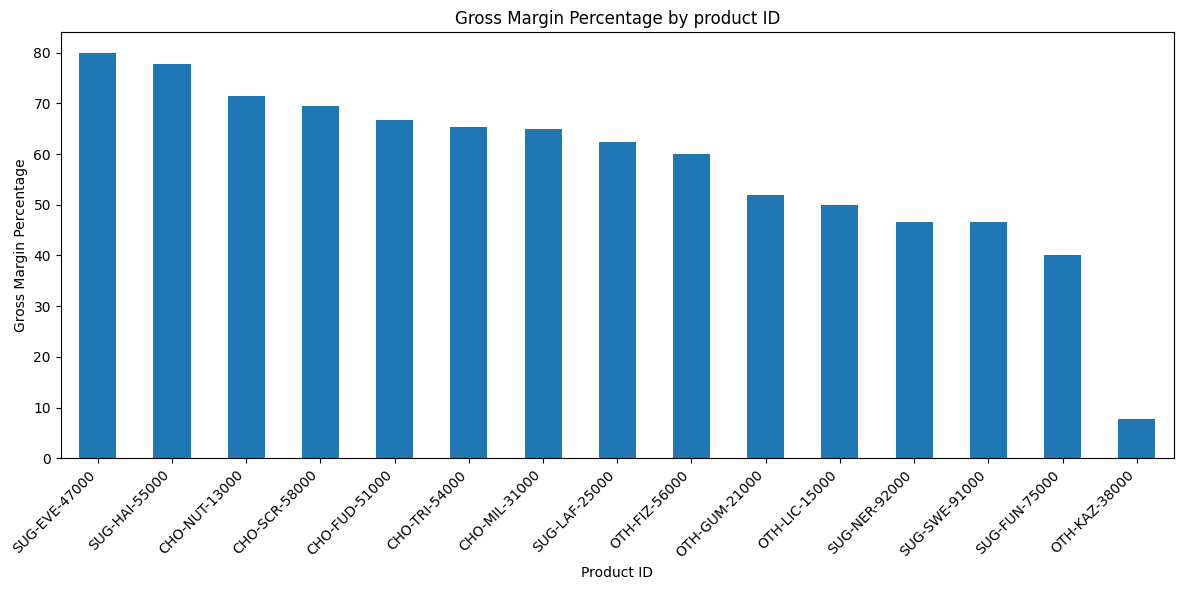

In [ ]:
#visualize the result
Product_name["Gross Margin%"].plot(kind="bar",figsize=(12,6))
plt.title("Gross Margin Percentage by product ID")
plt.xlabel("Product ID")
plt.ylabel("Gross Margin Percentage")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

# **Checking wheather high sales products are profitable**

In [ ]:
Product_name=data.groupby('Product Name',dropna=False).agg(Total_Sales=("Sales","sum"),Total_Cost=("Cost","sum"),Total_Profit=("Gross Profit","sum"))
Product_name["Gross Margin%"]=np.where(Product_name['Total_Sales']>0,Product_name["Total_Profit"]/Product_name['Total_Sales']*100,np.nan)
#product with the highest sales
high_sales_product=Product_name.sort_values("Total_Sales",ascending=False)
display(high_sales_product.head(10))

,Total_Sales,Total_Cost,Total_Profit,Gross Margin%
Product Name,,,,
Wonka Bar - Triple Dazzle Caramel,28485.00,9874.80,18610.20,65.333333
Wonka Bar -Scrumdiddlyumptious,27874.80,8517.30,19357.50,69.444444
Wonka Bar - Milk Chocolate,26867.75,9424.38,17443.37,64.923077
Wonka Bar - Fudge Mallows,24890.40,8296.80,16593.60,66.666667
Wonka Bar - Nutty Crunch Surprise,23574.95,6755.00,16819.95,71.346705
Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
Kazookles,1205.75,1113.00,92.75,7.692308
Wonka Gum,597.50,286.80,310.70,52.000000
Everlasting Gobstopper,130.00,26.00,104.00,80.000000


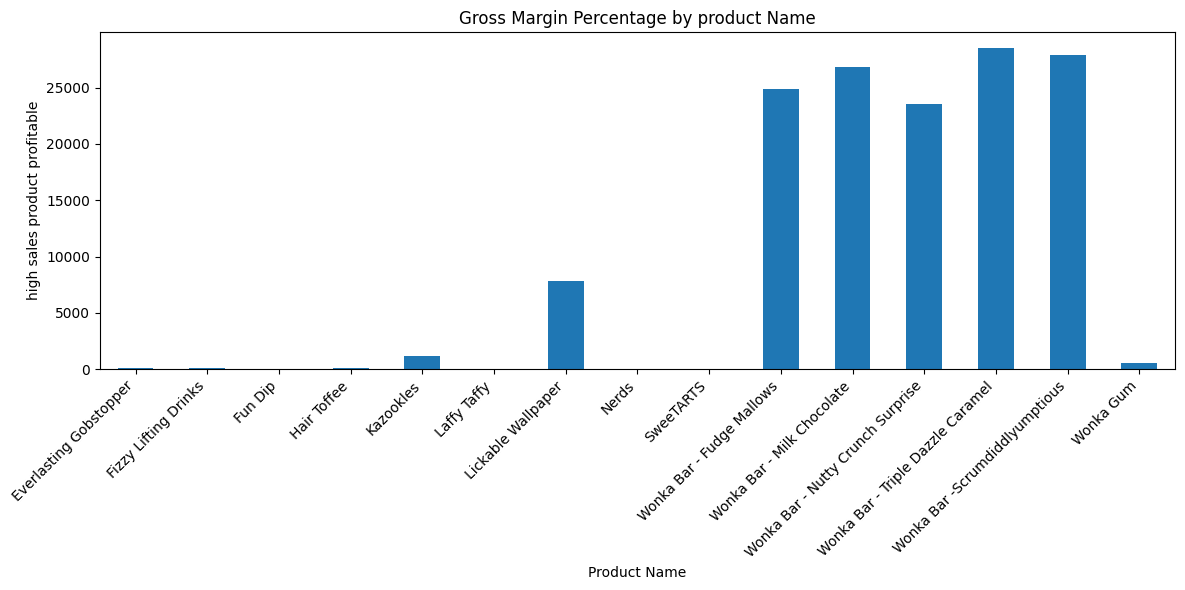

In [ ]:
Product_name["Total_Sales"].plot(kind="bar",figsize=(12,6))
plt.title("Gross Margin Percentage by product Name")
plt.xlabel("Product Name")
plt.ylabel("high sales product profitable")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [ ]:
Sales_cutoff=Product_name["Total_Sales"].quantile(0.75)
high_sales_low_margin=Product_name[(Product_name["Total_Sales"]>=Sales_cutoff)&(Product_name["Gross Margin%"]<10)]
display(high_sales_low_margin.sort_values("Gross Margin%"))
display(high_sales_low_margin.sort_values("Gross Margin%",ascending=False))
print("high sales cutoff(75th percentile):",Sales_cutoff)


,Total_Sales,Total_Cost,Total_Profit,Gross Margin%
Product Name,,,,


,Total_Sales,Total_Cost,Total_Profit,Gross Margin%
Product Name,,,,


high sales cutoff(75th percentile): 24232.675000000003


# **Comparing profitability across Divisions**

In [ ]:
division_analysis=data.groupby('Division',dropna=False).agg(Total_Sales=("Sales","sum"),Total_Cost=("Cost","sum"),Total_Profit=("Gross Profit","sum"))
division_analysis["Gross Margin%"]=np.where(division_analysis['Total_Sales']>0,division_analysis["Total_Profit"]/division_analysis['Total_Sales']*100,np.nan)
display(division_analysis.sort_values("Total_Profit",ascending=False))


,Total_Sales,Total_Cost,Total_Profit,Gross Margin%
Division,,,,
Chocolate,131692.90,42868.28,88824.62,67.448298
Other,9663.25,5329.80,4333.45,44.844643
Sugar,427.48,142.75,284.73,66.606625


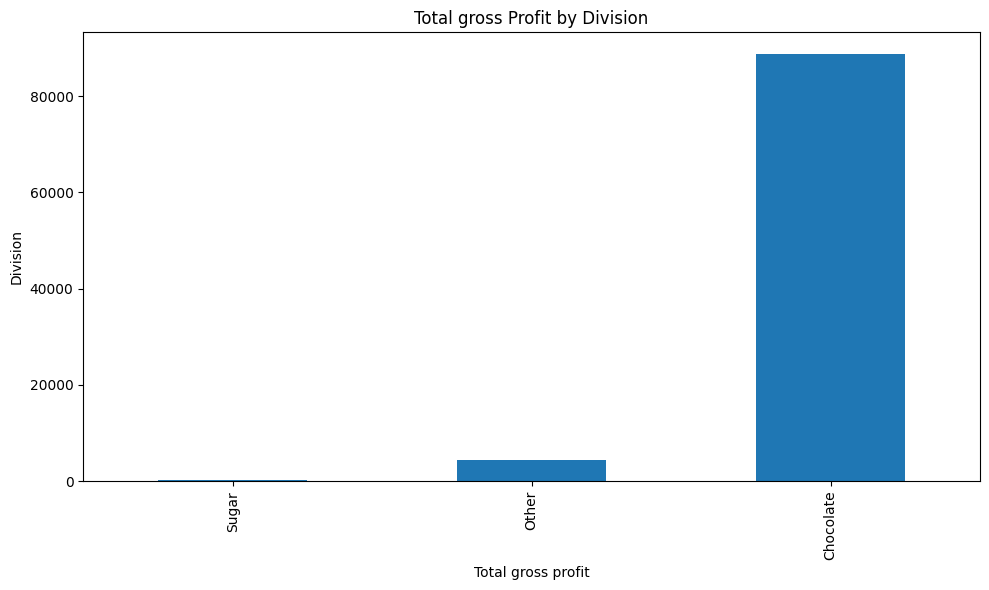

In [ ]:
division_analysis["Total_Profit"].sort_values().plot(kind="bar",figsize=(10,6))
plt.title("Total gross Profit by Division")
plt.xlabel("Total gross profit")
plt.ylabel("Division")
plt.tight_layout()
plt.show()

# **Identifiying products at margin risk**

In [ ]:
def classify_margin(margin):
  if pd.isna(margin):
    return "Not avaliable"
  elif margin<0:
    return "loss-making"
  elif margin<10:
    return "High risk"
  elif margin<20:
    return "moderate risk"
  else:
    return "healthy margin"
Product_name["Margin Risk"]=(Product_name["Gross Margin%"].apply(classify_margin))
display(Product_name.sort_values("Gross Margin%").head(20))


,Total_Sales,Total_Cost,Total_Profit,Gross Margin%,Margin Risk
Product Name,,,,,
Kazookles,1205.75,1113.00,92.75,7.692308,High risk
Fun Dip,12.00,7.20,4.80,40.000000,healthy margin
Nerds,15.00,8.00,7.00,46.666667,healthy margin
SweeTARTS,61.50,32.80,28.70,46.666667,healthy margin
Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000,healthy margin
Wonka Gum,597.50,286.80,310.70,52.000000,healthy margin
Fizzy Lifting Drinks,78.75,31.50,47.25,60.000000,healthy margin
Laffy Taffy,53.73,20.25,33.48,62.311558,healthy margin
Wonka Bar - Milk Chocolate,26867.75,9424.38,17443.37,64.923077,healthy margin


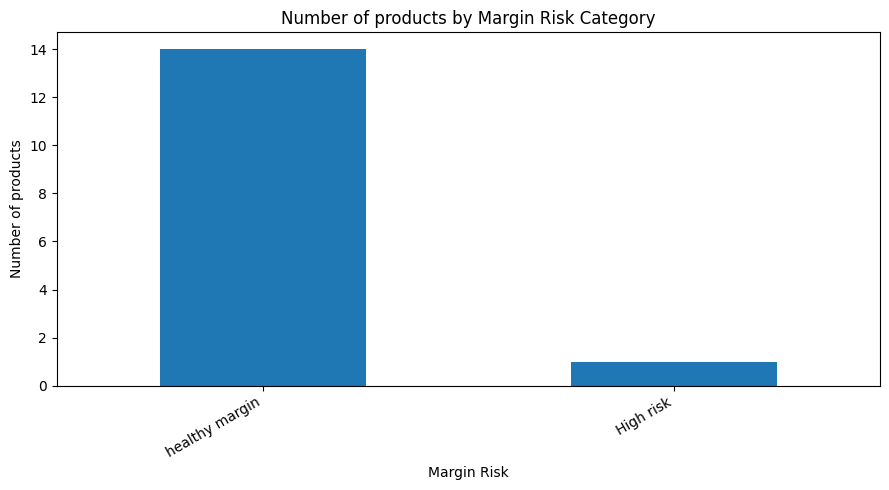

In [ ]:
#ploting the margin risk categories
risk_counts=Product_name["Margin Risk"].value_counts()
risk_counts.plot(kind="bar",figsize=(9,5))
plt.title("Number of products by Margin Risk Category")
plt.xlabel("Margin Risk")
plt.ylabel("Number of products")
plt.xticks(rotation=30,ha="right")
plt.tight_layout()
plt.show()

# **histogram graph for Sales,Cost,units,Gross Profit and Product Name,Region,Division**

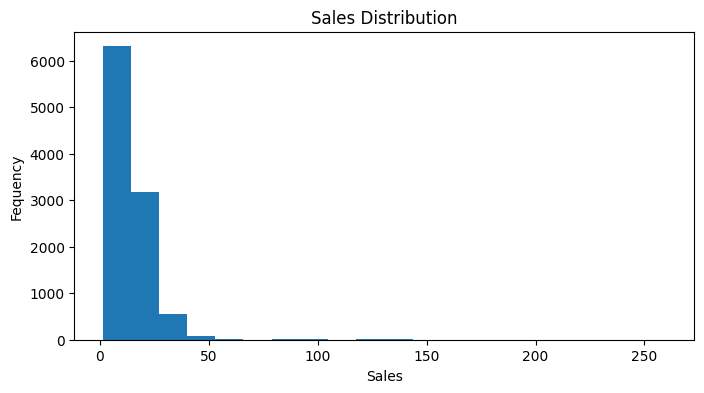

In [ ]:
# Histogram graph for sales
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.hist(data['Sales'].dropna(),bins=20)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Fequency")
plt.show()

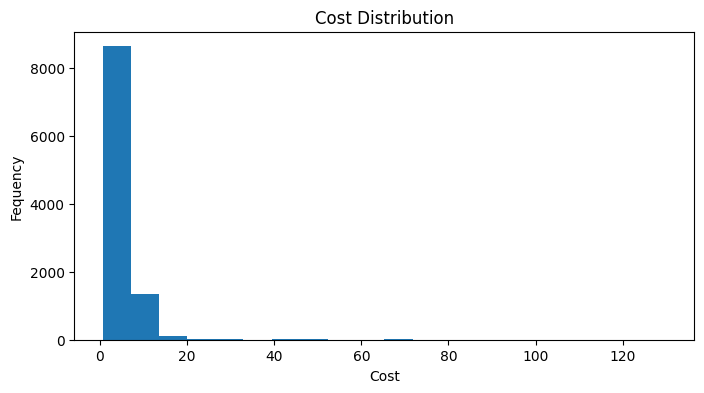

In [ ]:
# Histogram graph for Cost
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.hist(data['Cost'].dropna(),bins=20)
plt.title("Cost Distribution")
plt.xlabel("Cost")
plt.ylabel("Fequency")
plt.show()

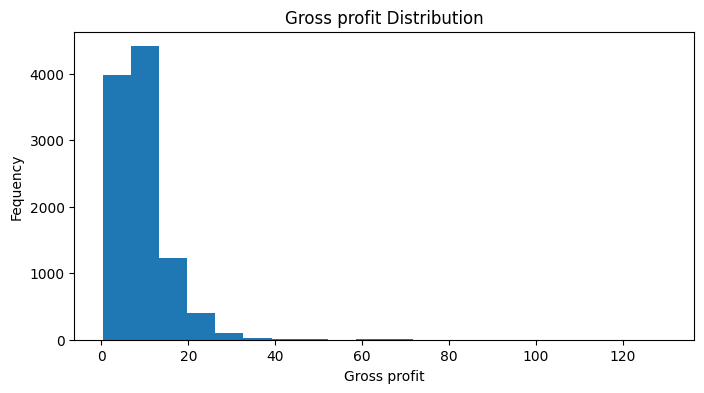

In [ ]:
#histograph graph for Gross Profit
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.hist(data['Gross Profit'].dropna(),bins=20)
plt.title("Gross profit Distribution")
plt.xlabel("Gross profit")
plt.ylabel("Fequency")
plt.show()


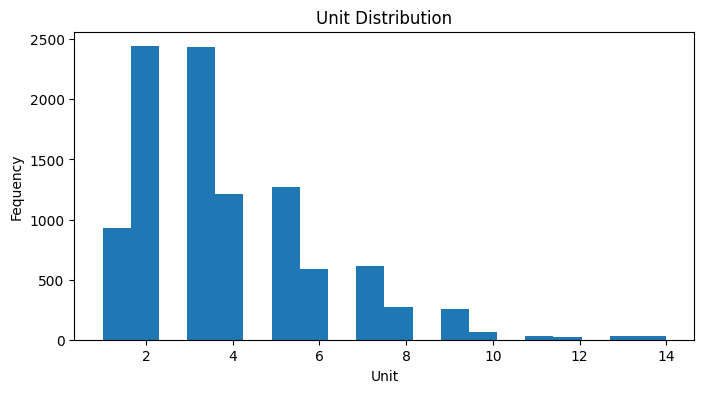

In [ ]:
#histogram graph for Unit
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.hist(data['Units'].dropna(),bins=20)
plt.title("Unit Distribution")
plt.xlabel("Unit")
plt.ylabel("Fequency")
plt.show()

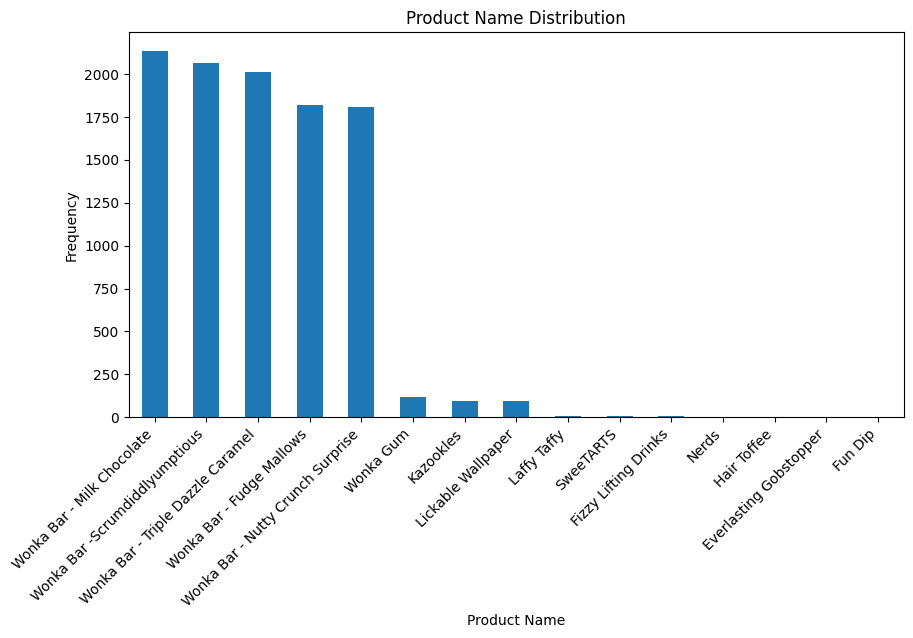

In [ ]:
#Bar graph for Product Name
import matplotlib.pyplot as plt
data['Product Name'].value_counts().plot(kind='bar',figsize=(10,5))
plt.title("Product Name Distribution")
plt.xlabel("Product Name")
plt.ylabel("Frequency")
plt.xticks(rotation=45,ha='right')
plt.show()

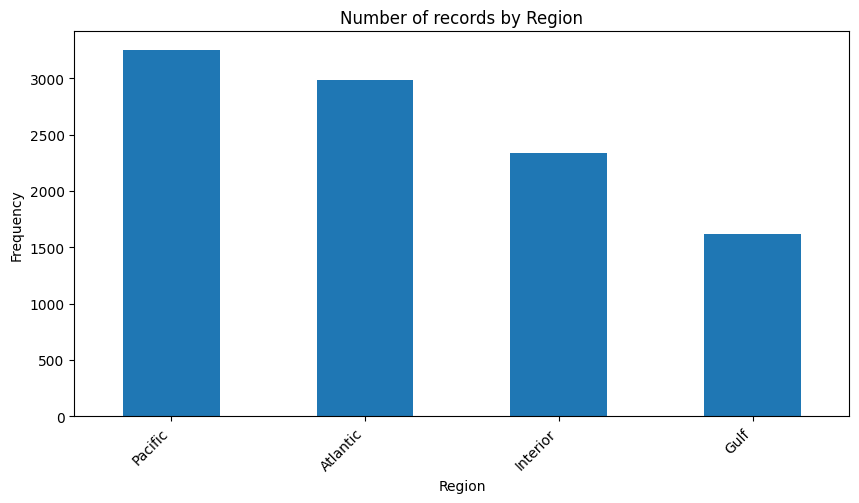

In [ ]:
#bar graph for Region
import matplotlib.pyplot as plt
data['Region'].value_counts().plot(kind='bar',figsize=(10,5))
plt.title("Number of records by Region")
plt.xlabel("Region")
plt.ylabel("Frequency")
plt.xticks(rotation=45,ha='right')
plt.show()

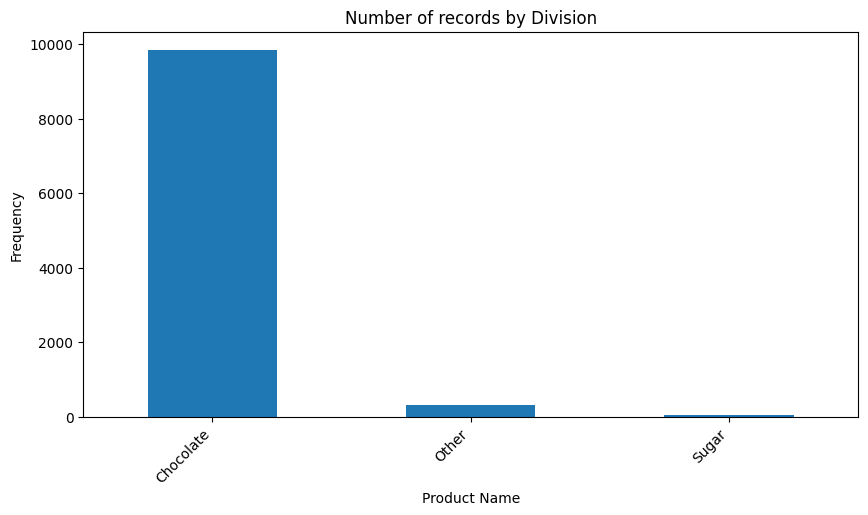

In [ ]:
#Bar graph for Division
import matplotlib.pyplot as plt
data['Division'].value_counts().plot(kind='bar',figsize=(10,5))
plt.title("Number of records by Division")
plt.xlabel("Product Name")
plt.ylabel("Frequency")
plt.xticks(rotation=45,ha='right')
plt.show()

# **Data Cleaning and validation**


# *Validate cost and sales value
# *  Remove zero-sales or invalid profit records


# *   Handle missing unit values
# *   standardize Product and division labels



















# **Validating Cost and Sales Values**

In [ ]:
#validate cost and sales value
data[['Sales','Cost']].describe()

,Sales,Cost
count,10194.000000,10194.000000
mean,13.908537,4.742087
std,11.341020,5.061647
min,1.250000,0.600000
25%,7.200000,2.400000
50%,10.800000,3.600000
75%,18.000000,5.700000
max,260.000000,130.000000


In [ ]:
#Checking negative sales
print("Nagitive sales:",(data['Sales']<0).sum())
#checking Zero sales
print("Zero sales:",(data['Sales']==0).sum())
#checking negative cost
print("Nagitive Cost:",(data['Cost']<0).sum())
#checking Zero cost
print("Zero cost:",(data['Cost']==0).sum())

Nagitive sales: 0
Zero sales: 0
Nagitive Cost: 0
Zero cost: 0


# **Removing Zero sales or invalid profit records**

In [ ]:
# calculating expected values
data['Profit']=data['Sales']-data['Cost']
#remove records with missing or invalid financial values
data=data.dropna(subset=['Sales','Cost','Profit'])
#remove zero or negative sales and negative costs
data=data[(data['Sales']>0)&(data['Cost']>=0)].copy()
#removr infinite values
data=data[np.isfinite(data[['Sales','Cost','Profit']]).all(axis=1)].copy()
print("rows after cleaning:",len(data))
print(data.head())

rows after cleaning: 10194
   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0       77095  Chocolate  Interior  CHO-MIL-3100

## **Handle Missing UNit values**

In [ ]:
#convert units into numeric format
data['Units']=pd.to_numeric(data['Units'],errors='coerce')
#check missing unit values
print("Missing Units:",data['Units'].isna().sum())
#replace missing units with the median units for that product
data['Units']=data.groupby("Product Name")['Units'].transform(lambda X:X.fillna(X.median()))
#if any missing values remain ,replace with thw over all median
data['Units']=data['Units'].fillna(data['Units'].median())
print(data[['Product Name','Units']].head())

Missing Units: 0
                        Product Name  Units
0         Wonka Bar - Milk Chocolate      2
1  Wonka Bar - Triple Dazzle Caramel      2
2  Wonka Bar - Nutty Crunch Surprise      3
3     Wonka Bar -Scrumdiddlyumptious      3
4  Wonka Bar - Triple Dazzle Caramel      3


# **Standardize product and division labels**

In [ ]:
#remove extra spaces and standardize capitalization
data['Product Name']=(data['Product Name'].astype('string').str.strip().str.replace('r\s+','',regex=True).str.title())
data['Division']=(data['Division'].astype('string').str.strip().str.replace('r\s+','',regex=True).str.title())
#check standardized labels
print("Product Name")
print(data['Product Name'].unique())
print('\nDivisions')
print(data['Division'].unique())

Product Name
<StringArray>
[       'Wonka Ba- Milk Chocolate', 'Wonka Ba- Triple Dazzle Caramel',
 'Wonka Ba- Nutty Crunch Surprise',    'Wonka Ba-Scrumdiddlyumptious',
         'Wonka Ba- Fudge Mallows',                       'Wonka Gum',
                       'Kazookles',              'Lickable Wallpaper',
            'Fizzy Lifting Drinks',                     'Laffy Taffy',
                       'Sweetarts',                           'Nerds',
                       'Haitoffee',          'Everlasting Gobstopper',
                         'Fun Dip']
Length: 15, dtype: string

Divisions
<StringArray>
['Chocolate', 'Other', 'Sugar']
Length: 3, dtype: string


<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:3: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_549/1023379120.py:2: SyntaxWarning: invalid escape sequence '\s'
  data['Product Name']=(data['Product Name'].astype('string').str.strip().str.replace('r\s+','',regex=True).str.title())
/tmp/ipykernel_549/1023379120.py:3: SyntaxWarning: invalid escape sequence '\s'
  data['Division']=(data['Division'].astype('string').str.strip().str.replace('r\s+','',regex=True).str.title())


# *verify the cleaned dataset**

In [ ]:
#check missing values
print("Missing values:",data.isnull().sum())
#check duplicate records
print("Duplicate rows:",data.duplicated().sum())
#display cleaned data
print(data.head())
#check data dimensions
print("rows and columns:",data.shape)
#save the cleaned data set
data.to_csv('/content/Nassau Candy Distributor.csv',index=False)

Missing values: Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
Profit            0
dtype: int64
Duplicate rows: 0
   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Cl

# *Profitability* Metric Calculation
**For** **each** **product**


*  Gross Margin(%)
*   Profit Per Unit


*   Total Profit Contribution












In [ ]:
#Gross Margin(%)
data['Gross Profit']=data['Sales']-data['Cost']
#calculating  gross profit percentage
data['Gross Margin%']=(data['Gross Profit']/data['Sales'])*100
#displaying gross margin for each product
print(data[['Product Name','Sales','Cost','Gross Profit']])

                            Product Name  Sales  Cost  Gross Profit
0             Wonka Bar - Milk Chocolate   6.50  2.28          4.22
1      Wonka Bar - Triple Dazzle Caramel   7.50  2.60          4.90
2      Wonka Bar - Nutty Crunch Surprise  10.47  3.00          7.47
3         Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50
4      Wonka Bar - Triple Dazzle Caramel  11.25  3.90          7.35
...                                  ...    ...   ...           ...
10189         Wonka Bar - Milk Chocolate   9.75  3.42          6.33
10190  Wonka Bar - Nutty Crunch Surprise   6.98  2.00          4.98
10191     Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50
10192  Wonka Bar - Triple Dazzle Caramel  26.25  9.10         17.15
10193     Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50

[10194 rows x 4 columns]


In [ ]:
#Profit per unit
data['Profit Per Unit']=data['Gross Profit']/data['Units']
#displaying profit per unit for each product
print(data[['Product Name','Units','Gross Profit','Profit Per Unit']])

                            Product Name  Units  Gross Profit  Profit Per Unit
0             Wonka Bar - Milk Chocolate      2          4.22             2.11
1      Wonka Bar - Triple Dazzle Caramel      2          4.90             2.45
2      Wonka Bar - Nutty Crunch Surprise      3          7.47             2.49
3         Wonka Bar -Scrumdiddlyumptious      3          7.50             2.50
4      Wonka Bar - Triple Dazzle Caramel      3          7.35             2.45
...                                  ...    ...           ...              ...
10189         Wonka Bar - Milk Chocolate      3          6.33             2.11
10190  Wonka Bar - Nutty Crunch Surprise      2          4.98             2.49
10191     Wonka Bar -Scrumdiddlyumptious      3          7.50             2.50
10192  Wonka Bar - Triple Dazzle Caramel      7         17.15             2.45
10193     Wonka Bar -Scrumdiddlyumptious      3          7.50             2.50

[10194 rows x 4 columns]


In [ ]:
#Total Profit contribution
Product_Profit=data.groupby('Product Name',dropna=False).agg(Total_Sales=("Sales","sum"),Total_Cost=("Cost","sum"),Total_Profit=("Gross Profit","sum"))
Product_Profit["Gross Margin%"]=np.where(Product_Profit['Total_Sales']>0,Product_Profit["Total_Profit"]/Product_Profit['Total_Sales']*100,np.nan)
display(Product_Profit.sort_values("Total_Profit",ascending=False))

,Total_Sales,Total_Cost,Total_Profit,Gross Margin%
Product Name,,,,
Wonka Bar -Scrumdiddlyumptious,27874.80,8517.30,19357.50,69.444444
Wonka Bar - Triple Dazzle Caramel,28485.00,9874.80,18610.20,65.333333
Wonka Bar - Milk Chocolate,26867.75,9424.38,17443.37,64.923077
Wonka Bar - Nutty Crunch Surprise,23574.95,6755.00,16819.95,71.346705
Wonka Bar - Fudge Mallows,24890.40,8296.80,16593.60,66.666667
Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000
Wonka Gum,597.50,286.80,310.70,52.000000
Everlasting Gobstopper,130.00,26.00,104.00,80.000000
Kazookles,1205.75,1113.00,92.75,7.692308


# **Product Level Profitability Analysis**

## *  **Rank Products By**
*   Gross Profit


*   Gross Margin


# *   **Identify:**
*   High-Profit/high-margin products

*   High-Sales/ Low - margin products
*   Low -Sales/low-profit products








   






In [ ]:
#Rank products by
#gross profit
profit_ranking=data.sort_values(by='Gross Profit',ascending=False)
profit_ranking['Gross Profit Rank']=profit_ranking['Gross Profit'].rank(ascending=False)
print(profit_ranking[['Product Name','Sales','Gross Profit']])
#Gross Margin
margin=data.sort_values(by='Gross Margin%',ascending=False)
margin['Gross Margin Rank']=margin['Gross Margin%'].rank(ascending=False)
print(margin[['Product Name','Sales','Gross Profit']])

            Product Name   Sales  Gross Profit
365   Lickable Wallpaper  260.00        130.00
5827  Lickable Wallpaper  220.00        110.00
6472  Lickable Wallpaper  200.00        100.00
4831  Lickable Wallpaper  200.00        100.00
8534  Lickable Wallpaper  180.00         90.00
...                  ...     ...           ...
6732           Kazookles    3.25          0.25
763            Kazookles    3.25          0.25
8979           Kazookles    3.25          0.25
3237           Kazookles    3.25          0.25
785            Kazookles    3.25          0.25

[10194 rows x 3 columns]
                Product Name  Sales  Gross Profit
8935  Everlasting Gobstopper  30.00         24.00
4729  Everlasting Gobstopper  40.00         32.00
5913  Everlasting Gobstopper  60.00         48.00
4435             Hair Toffee  22.50         17.50
4956             Hair Toffee  22.50         17.50
...                      ...    ...           ...
495                Kazookles   9.75          0.75
5221      

In [ ]:
#identify High-profit /high margin products
high_profit=data[data['Gross Profit']>20]
print("High Profit Products:")
print(high_profit[['Product Name','Gross Profit']])
high_margin=data[data['Gross Margin%']>20]
print("\nHigh Margin Products:")
print(high_margin[['Product Name','Gross Margin%']])

High Profit Products:
                            Product Name  Gross Profit
5         Wonka Bar -Scrumdiddlyumptious         22.50
40             Wonka Bar - Fudge Mallows         24.00
65            Wonka Bar - Milk Chocolate         21.10
76            Wonka Bar - Milk Chocolate         27.43
117           Wonka Bar - Milk Chocolate         29.54
...                                  ...           ...
10000                 Lickable Wallpaper         50.00
10027          Wonka Bar - Fudge Mallows         31.20
10030     Wonka Bar -Scrumdiddlyumptious         22.50
10101                 Lickable Wallpaper         40.00
10135  Wonka Bar - Triple Dazzle Caramel         31.85

[436 rows x 2 columns]

High Margin Products:
                            Product Name  Gross Margin%
0             Wonka Bar - Milk Chocolate      64.923077
1      Wonka Bar - Triple Dazzle Caramel      65.333333
2      Wonka Bar - Nutty Crunch Surprise      71.346705
3         Wonka Bar -Scrumdiddlyumptious      6

In [ ]:
#high - sales/ LOw margin products
high_sales_low_margin=data[(data['Sales']>=3)&(data['Gross Margin%']<=20)]
print("High Sales and Low Margin Products:")
print(high_sales_low_margin[['Product Name','Sales','Gross Margin%']])

High Sales and Low Margin Products:
      Product Name  Sales  Gross Margin%
26       Kazookles   9.75       7.692308
92       Kazookles  13.00       7.692308
160      Kazookles  19.50       7.692308
200      Kazookles   9.75       7.692308
210      Kazookles  13.00       7.692308
...            ...    ...            ...
9259     Kazookles   9.75       7.692308
9357     Kazookles  13.00       7.692308
9699     Kazookles   9.75       7.692308
9859     Kazookles   3.25       7.692308
10009    Kazookles  16.25       7.692308

[96 rows x 3 columns]


In [ ]:
#low -sales/low profit products
low_sales_low_profit=data[(data['Sales']<=2)&(data['Gross Profit']<=2)]
print("Low Sales and Low Profit Products:")
print(low_sales_low_profit[['Product Name','Sales','Gross Profit']])

Low Sales and Low Profit Products:
     Product Name  Sales  Gross Profit
19      Wonka Gum   1.25          0.65
788     Wonka Gum   1.25          0.65
1018    Wonka Gum   1.25          0.65
1802    Wonka Gum   1.25          0.65
2466  Laffy Taffy   1.99          1.24
3601    Wonka Gum   1.25          0.65
5029      Fun Dip   1.50          0.60
5305    Wonka Gum   1.25          0.65
5643  Laffy Taffy   1.99          1.24
6116    Wonka Gum   1.25          0.65
6598    Wonka Gum   1.25          0.65
6900  Laffy Taffy   1.99          1.24
6913    Wonka Gum   1.25          0.65
7149        Nerds   1.50          0.70
7186    Wonka Gum   1.25          0.65
7313    Wonka Gum   1.25          0.65
7595    Wonka Gum   1.25          0.65
9909    Wonka Gum   1.25          0.65


In [ ]:
#calculate total gross profit for the entire business
Total_Sales=data['Sales'].sum()
Total_Cost=data['Cost'].sum()
Total_Profit=data['Gross Profit'].sum()
overall_gross_margin=Total_Profit/Total_Sales*100
print("Total Sales:",Total_Sales)
print("Total Cost:",Total_Cost)
print("Total Profit:",Total_Profit)
print("Overall Gross Margin:",round(overall_gross_margin,2),"%")

Total Sales: 141783.63
Total Cost: 48340.83
Total Profit: 93442.80000000002
Overall Gross Margin: 65.91 %


# **Division-level performance Analysis**


*   Aggregate metrics by Division
*   Compare:

*   Average margin by division
*   Revenue vs profit imbalance


*   identify divisions with:
      

* strong financial efficiency
*   structural margin issues










In [ ]:
#aggregate metrics by division
division_analysis=data.groupby('Division').agg(Total_Sales=("Sales",'sum'),Total_Cost=("Cost",'sum'),Total_Profit=("Gross Profit",'sum'),
Average_product_margin=("Gross Profit",'mean')).reset_index()
division_analysis["Gross Profit"]=(division_analysis["Total_Profit"]/division_analysis["Total_Sales"]*100)
print(division_analysis.round(2))

    Division  Total_Sales  Total_Cost  Total_Profit  Average_product_margin  \
0  Chocolate    131692.90    42868.28      88824.62                    9.02   
1      Other      9663.25     5329.80       4333.45                   13.98   
2      Sugar       427.48      142.75        284.73                    7.12   

   Gross Profit  
0         67.45  
1         44.84  
2         66.61  


In [ ]:
#comparing avegare margin by division
margin_by_division=data.groupby('Division').agg(Average_product_margin=("Gross Profit",'mean')).reset_index()
print(margin_by_division.round(2))

    Division  Average_product_margin
0  Chocolate                    9.02
1      Other                   13.98
2      Sugar                    7.12


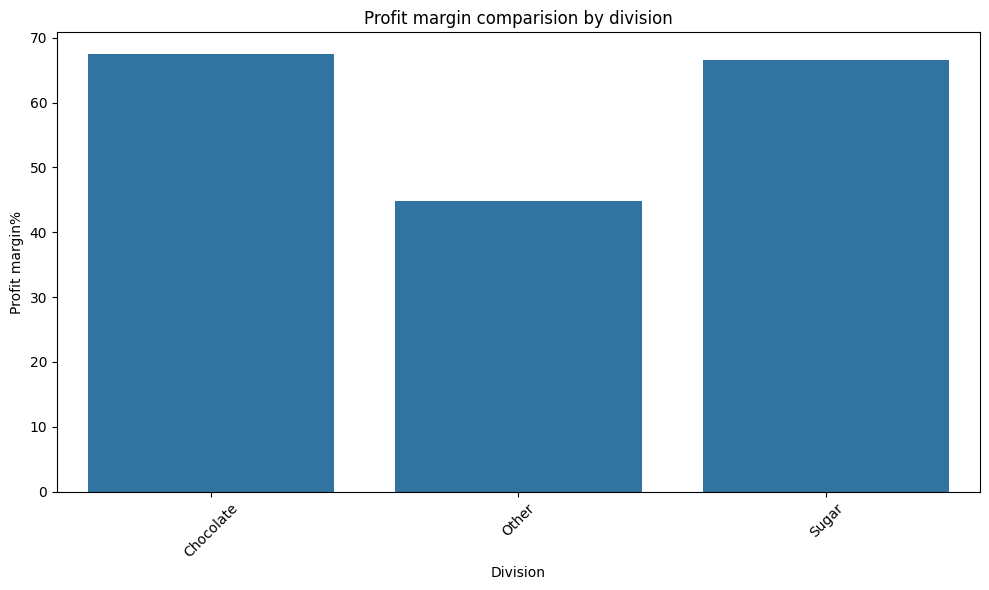

In [ ]:
#margin comparision graph
plt.figure(figsize=(10,6))
sns.barplot(data=division_analysis,x='Division',y='Gross Profit')
plt.title("Profit margin comparision by division")
plt.xlabel("Division")
plt.ylabel("Profit margin%")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#analyzing revenue vs profit imbalance
total_revenue_by_division=data.groupby('Division').agg(Total_Revenue=("Sales",'sum')).reset_index()
Total_Profit_by_division=data.groupby('Division').agg(Total_Profit=("Gross Profit",'sum')).reset_index()
revenue_profit_imbalance=pd.merge(total_revenue_by_division,Total_Profit_by_division,on='Division')
revenue_profit_imbalance['Gross Profit']=(revenue_profit_imbalance['Total_Revenue']/revenue_profit_imbalance['Total_Profit']*100)
print(revenue_profit_imbalance.round(2))


    Division  Total_Revenue  Total_Profit  Gross Profit
0  Chocolate      131692.90      88824.62        148.26
1      Other        9663.25       4333.45        222.99
2      Sugar         427.48        284.73        150.14


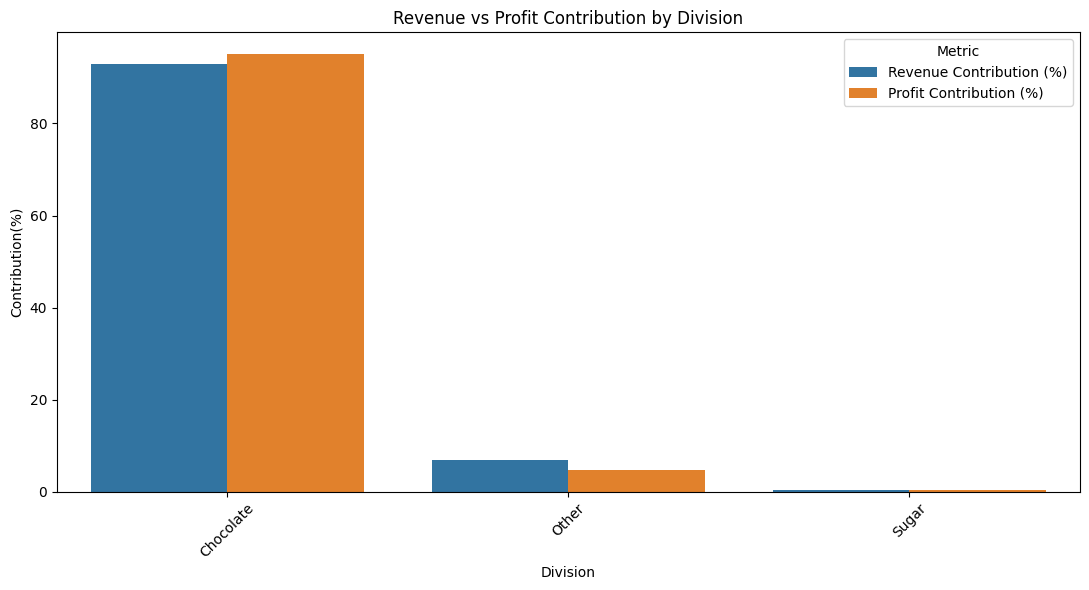

In [ ]:
# revenue vs profit contribution graph
# Calculate totals
total_sales = division_analysis['Total_Sales'].sum()
total_profit = division_analysis['Total_Profit'].sum()

# Calculate percentage contributions
division_analysis['Revenue Contribution (%)'] = (division_analysis['Total_Sales'] / total_sales) * 100
division_analysis['Profit Contribution (%)'] = (division_analysis['Total_Profit'] / total_profit) * 100

# Melt the dataframe into a long-form structure suitable for sns.barplot with hue
contribution_df = division_analysis.melt(
    id_vars='Division',
    value_vars=['Revenue Contribution (%)', 'Profit Contribution (%)'],
    var_name='Metric',
    value_name='Contribution(%)'
)

# Plotting
plt.figure(figsize=(11,6))
sns.barplot(data=contribution_df, x='Division', y='Contribution(%)', hue='Metric')
plt.title("Revenue vs Profit Contribution by Division")
plt.xlabel("Division")
plt.ylabel("Contribution(%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#identifying divisions with strong financial efficiency
def classify_efficiency(row):
  # Since we are grouped by Division, we evaluate efficiency using the calculated 'Gross Profit' margin (%)
  if row['Gross Profit'] >= 65:
    return 'Strong Financial Efficiency'
  elif row['Gross Profit'] < 50:
    return 'Needs Improvement'
  else:
    return 'Moderate Performance'

division_analysis['Efficiency_Status'] = division_analysis.apply(classify_efficiency, axis=1)
print(division_analysis[['Division', 'Total_Sales', 'Total_Profit', 'Gross Profit', 'Efficiency_Status']].round(2))

    Division  Total_Sales  Total_Profit  Gross Profit  \
0  Chocolate    131692.90      88824.62         67.45   
1      Other      9663.25       4333.45         44.84   
2      Sugar       427.48        284.73         66.61   

             Efficiency_Status  
0  Strong Financial Efficiency  
1            Needs Improvement  
2  Strong Financial Efficiency  


In [ ]:
#identifying structural margin issues
def identify_margin_issues(row):
  if row['Gross Profit ']<0:
    return 'Loss Making Division'
  elif []

,Division,Total_Sales,Total_Profit,Gross Profit,Margin_Risk_Status
0,Chocolate,131692.90,88824.62,67.45,Structurally Healthy Margin
1,Other,9663.25,4333.45,44.84,Underperforming Margin Risk
2,Sugar,427.48,284.73,66.61,Structurally Healthy Margin


# **Profit Concentration (pareto) Analysis**


*   Determine % of products contributing
*   80% of revenue

*   80% of profit
*   Detect congestion -prone states or regionidentify over-dependency risks





In [ ]:
#calculating Revenue and Profit
#convert values to numeric
data['Sales']=pd.to_numeric(data['Sales'],errors='coerce')
data['Cost']=pd.to_numeric(data['Cost'],errors='coerce')
data['Gross Profit']=pd.to_numeric(data['Gross Profit'],errors='coerce')
#calculating total revenue and total profit
total_revenue=data['Sales'].sum()
total_profit=data['Gross Profit'].sum()
#calculating revenue and profit contribution
data['Revenue Contribution']=data['Sales']/total_revenue*100
data['Profit Contribution']=data['Gross Profit']/total_profit*100
display(data[['Product Name', 'Sales','Gross Profit', 'Revenue Contribution', 'Profit Contribution']])

,Product Name,Sales,Gross Profit,Revenue Contribution,Profit Contribution
0,Wonka Bar - Milk Chocolate,6.50,4.22,0.004584,0.004516
1,Wonka Bar - Triple Dazzle Caramel,7.50,4.90,0.005290,0.005244
2,Wonka Bar - Nutty Crunch Surprise,10.47,7.47,0.007384,0.007994
3,Wonka Bar -Scrumdiddlyumptious,10.80,7.50,0.007617,0.008026
4,Wonka Bar - Triple Dazzle Caramel,11.25,7.35,0.007935,0.007866
...,...,...,...,...,...
10189,Wonka Bar - Milk Chocolate,9.75,6.33,0.006877,0.006774
10190,Wonka Bar - Nutty Crunch Surprise,6.98,4.98,0.004923,0.005329
10191,Wonka Bar -Scrumdiddlyumptious,10.80,7.50,0.007617,0.008026
10192,Wonka Bar - Triple Dazzle Caramel,26.25,17.15,0.018514,0.018353


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
#calculating 80% of revenue and 80% of profit
total_revenue=data['Sales'].sum()
total_profit=data['Gross Profit'].sum()
revenue_80_percent=total_revenue*0.8
profit_80_percent=total_profit*0.8
print("Total_revenue:",total_revenue)
print("80% of Revenue:",revenue_80_percent)
print("Total_Profit:",total_profit)
print("80% of profit:",profit_80_percent)


Total_revenue: 141783.63
80% of Revenue: 113426.90400000001
Total_Profit: 93442.8
80% of profit: 74754.24


# **Cost Structure Diagnostics**


*   **Cost** **vs** **sales** **scatter** **analysis**
*   **identify:**


*   **cost-heavy , margin -poor products**
*   **pricing inefficiencies**


*   **Flag Products needing**
*   **repricing**


*   **Cost renegotiation**
*   **Discontinuation review**









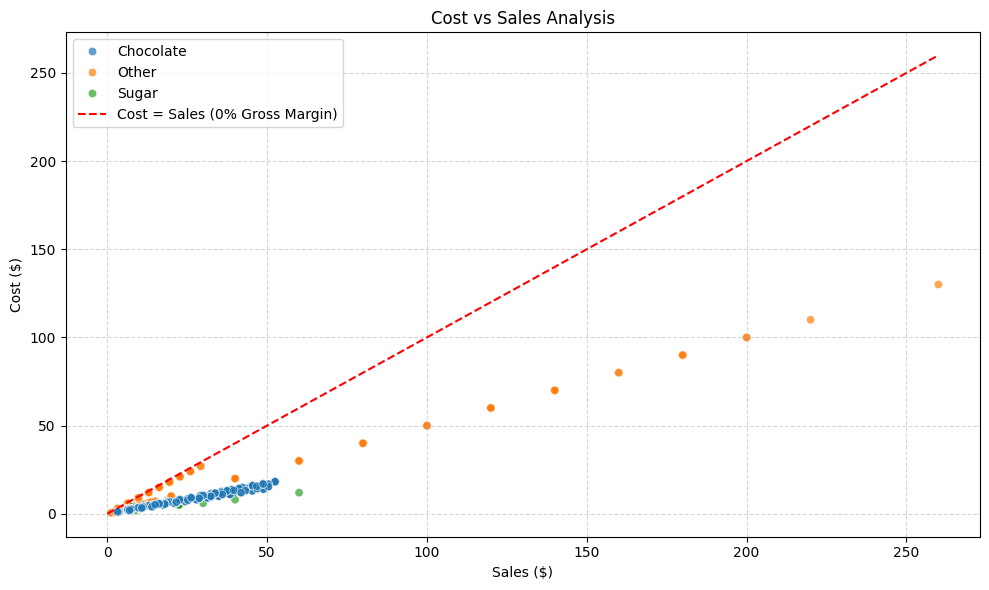

In [ ]:
#cost vs sales scatter analysis
import matplotlib.pyplot as plt
import seaborn as sns

# Cost vs Sales Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='Sales', y='Cost', hue='Division', alpha=0.7)

# Diagonal break-even or reference line (where Cost = Sales)
max_val = max(data['Sales'].max(), data['Cost'].max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Cost = Sales (0% Gross Margin)')

plt.title('Cost vs Sales Analysis')
plt.xlabel('Sales ($)')
plt.ylabel('Cost ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
#identifying cost heavy and margin poor products
problem_product=data[(data['Cost']>10)&(data['Gross Profit']<20)]
print("Cost heavy and margin poor products:")
print(problem_product[['Product Name','Sales','Cost','Gross Profit']])


Cost heavy and margin poor products:
                            Product Name  Sales   Cost  Gross Profit
92                             Kazookles  13.00  12.00          1.00
160                            Kazookles  19.50  18.00          1.50
210                            Kazookles  13.00  12.00          1.00
245                            Kazookles  22.75  21.00          1.75
338           Wonka Bar - Milk Chocolate  29.25  10.26         18.99
...                                  ...    ...    ...           ...
10009                          Kazookles  16.25  15.00          1.25
10024         Wonka Bar - Milk Chocolate  29.25  10.26         18.99
10095  Wonka Bar - Triple Dazzle Caramel  30.00  10.40         19.60
10134         Wonka Bar - Milk Chocolate  29.25  10.26         18.99
10172  Wonka Bar - Triple Dazzle Caramel  30.00  10.40         19.60

[140 rows x 4 columns]


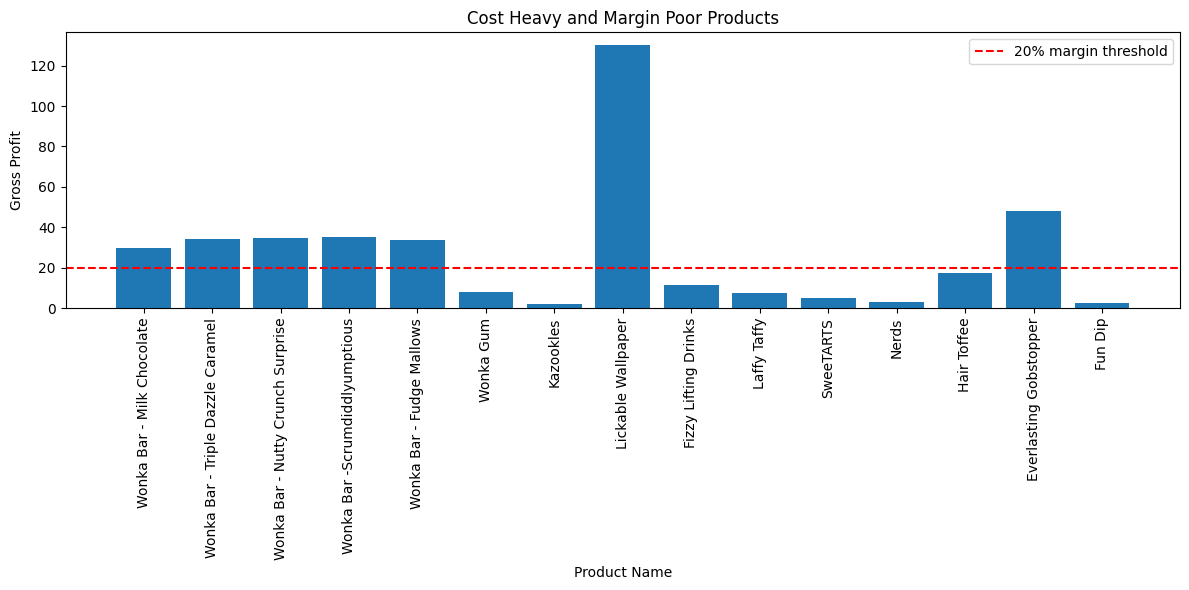

In [ ]:
from matplotlib.lines import lineStyles
#bar graph for cost heavy and margin poor products
plt.figure(figsize=(12,6))
plt.bar(data['Product Name'],data['Gross Profit'])
plt.axhline(y=20,color='red',lineStyle='--',label='20% margin threshold')
plt.xlabel('Product Name')
plt.ylabel('Gross Profit')
plt.title('Cost Heavy and Margin Poor Products')
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# findind pricing inefficiency
pricing_issues=data[data['Gross Profit']<20]
print("pricing inefficiency Products")
print(pricing_issues[['Product Name','Sales','Cost','Gross Profit']])

pricing inefficiency Products
                            Product Name  Sales  Cost  Gross Profit
0             Wonka Bar - Milk Chocolate   6.50  2.28          4.22
1      Wonka Bar - Triple Dazzle Caramel   7.50  2.60          4.90
2      Wonka Bar - Nutty Crunch Surprise  10.47  3.00          7.47
3         Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50
4      Wonka Bar - Triple Dazzle Caramel  11.25  3.90          7.35
...                                  ...    ...   ...           ...
10189         Wonka Bar - Milk Chocolate   9.75  3.42          6.33
10190  Wonka Bar - Nutty Crunch Surprise   6.98  2.00          4.98
10191     Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50
10192  Wonka Bar - Triple Dazzle Caramel  26.25  9.10         17.15
10193     Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50

[9685 rows x 4 columns]


In [ ]:
#repricing
target_margin=20
data['Sales']=(data['Cost']/(1-target_margin/100))
print(data[['Product Name','Sales','Cost']])


                            Product Name   Sales  Cost
0             Wonka Bar - Milk Chocolate   2.850  2.28
1      Wonka Bar - Triple Dazzle Caramel   3.250  2.60
2      Wonka Bar - Nutty Crunch Surprise   3.750  3.00
3         Wonka Bar -Scrumdiddlyumptious   4.125  3.30
4      Wonka Bar - Triple Dazzle Caramel   4.875  3.90
...                                  ...     ...   ...
10189         Wonka Bar - Milk Chocolate   4.275  3.42
10190  Wonka Bar - Nutty Crunch Surprise   2.500  2.00
10191     Wonka Bar -Scrumdiddlyumptious   4.125  3.30
10192  Wonka Bar - Triple Dazzle Caramel  11.375  9.10
10193     Wonka Bar -Scrumdiddlyumptious   4.125  3.30

[10194 rows x 3 columns]


In [ ]:
#cost renegotiation
target_margin=20
data['Cost']=(data['Sales']/(1+target_margin/100))
print(data[['Product Name','Cost','Sales']])

In [ ]:
import pandas as pd

# 1. Reload the clean data to restore original Sales and Cost columns
data = pd.read_csv('/content/Nassau Candy Distributor.csv')

# 2. Correct formula for renegotiation to achieve a 20% target margin:
# Target Cost = Sales * (1 - Target Margin %)
target_margin = 20
data['Target Cost (Renegotiated)'] = data['Sales'] * (1 - target_margin / 100)

# Display original Sales, original Cost, and the newly calculated target Cost
display(data[['Product Name', 'Sales', 'Cost', 'Target Cost (Renegotiated)']].head())

,Product Name,Sales,Cost,Target Cost (Renegotiated)
0,Wonka Bar - Milk Chocolate,6.50,2.28,5.200
1,Wonka Bar - Triple Dazzle Caramel,7.50,2.60,6.000
2,Wonka Bar - Nutty Crunch Surprise,10.47,3.00,8.376
3,Wonka Bar -Scrumdiddlyumptious,10.80,3.30,8.640
4,Wonka Bar - Triple Dazzle Caramel,11.25,3.90,9.000


In [ ]:
# Discontinuation Review Analysis
# We reload the clean dataset to ensure we have the correct original metrics
data_original = pd.read_csv('/content/Nassau Candy Distributor.csv')

# Calculate Gross Margin Percentage for analysis
data_original['Gross Profit'] = data_original['Sales'] - data_original['Cost']
data_original['Gross Margin%'] = (data_original['Gross Profit'] / data_original['Sales']) * 100

# Group by Product to see overall performance
product_summary = data_original.groupby('Product Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Gross Profit', 'sum'),
    Avg_Margin=('Gross Margin%', 'mean')
).reset_index()

# Criteria for Discontinuation Review:
# Flag products that have negative average margins or overall negative profit contribution
discontinuation_candidates = product_summary[
    (product_summary['Avg_Margin'] < 0) | (product_summary['Total_Profit'] <= 0)
]

print("--- Products Recommended for Discontinuation Review ---")
if discontinuation_candidates.empty:
    print("No products meet the criteria for discontinuation. All products are currently profitable overall!")
else:
    display(discontinuation_candidates.sort_values(by='Total_Profit'))

--- Products Recommended for Discontinuation Review ---
No products meet the criteria for discontinuation. All products are currently profitable overall!


# **Key Performance Indicators (KIPs)**


*   Gross Margin - Gross Profit%Sales
*   Profit Per Unit - Gross Profit % Units


*   Revenue Contribution - Product Sales% TotalSales
*   Profit Contribution - Product Profit % TOtal profit

*   Margin Volatality - Variability of margin over time








In [ ]:
#Gross margin%
data['Gross Profit']=data['Sales']-data['Cost']
data['Gross_Margin']=(data['Gross Profit']/data['Sales'])*100
print(data[['Product Name','Sales','Cost','Gross Profit','Gross_Margin']])

                            Product Name  Sales  Cost  Gross Profit  \
0             Wonka Bar - Milk Chocolate   6.50  2.28          4.22   
1      Wonka Bar - Triple Dazzle Caramel   7.50  2.60          4.90   
2      Wonka Bar - Nutty Crunch Surprise  10.47  3.00          7.47   
3         Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50   
4      Wonka Bar - Triple Dazzle Caramel  11.25  3.90          7.35   
...                                  ...    ...   ...           ...   
10189         Wonka Bar - Milk Chocolate   9.75  3.42          6.33   
10190  Wonka Bar - Nutty Crunch Surprise   6.98  2.00          4.98   
10191     Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50   
10192  Wonka Bar - Triple Dazzle Caramel  26.25  9.10         17.15   
10193     Wonka Bar -Scrumdiddlyumptious  10.80  3.30          7.50   

       Gross_Margin  
0         64.923077  
1         65.333333  
2         71.346705  
3         69.444444  
4         65.333333  
...            

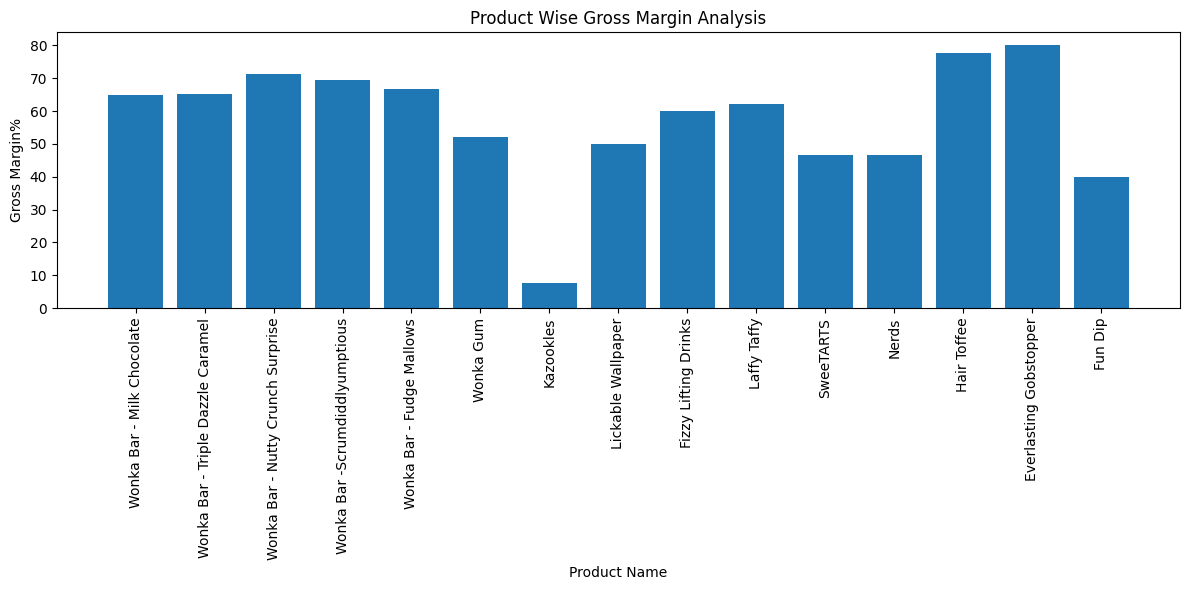

In [ ]:
plt.figure(figsize=(12,6))
plt.bar(data['Product Name'],data['Gross_Margin'])
plt.xlabel('Product Name')
plt.ylabel('Gross Margin%')
plt.title('Product Wise Gross Margin Analysis')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
#profit per unit
data['Profit_per_unit']=(data['Gross Profit']/data['Units'])
print(data[['Product Name','Units','Gross Profit','Profit_per_unit']])

                            Product Name  Units  Gross Profit  Profit_per_unit
0             Wonka Bar - Milk Chocolate      2          4.22             2.11
1      Wonka Bar - Triple Dazzle Caramel      2          4.90             2.45
2      Wonka Bar - Nutty Crunch Surprise      3          7.47             2.49
3         Wonka Bar -Scrumdiddlyumptious      3          7.50             2.50
4      Wonka Bar - Triple Dazzle Caramel      3          7.35             2.45
...                                  ...    ...           ...              ...
10189         Wonka Bar - Milk Chocolate      3          6.33             2.11
10190  Wonka Bar - Nutty Crunch Surprise      2          4.98             2.49
10191     Wonka Bar -Scrumdiddlyumptious      3          7.50             2.50
10192  Wonka Bar - Triple Dazzle Caramel      7         17.15             2.45
10193     Wonka Bar -Scrumdiddlyumptious      3          7.50             2.50

[10194 rows x 4 columns]


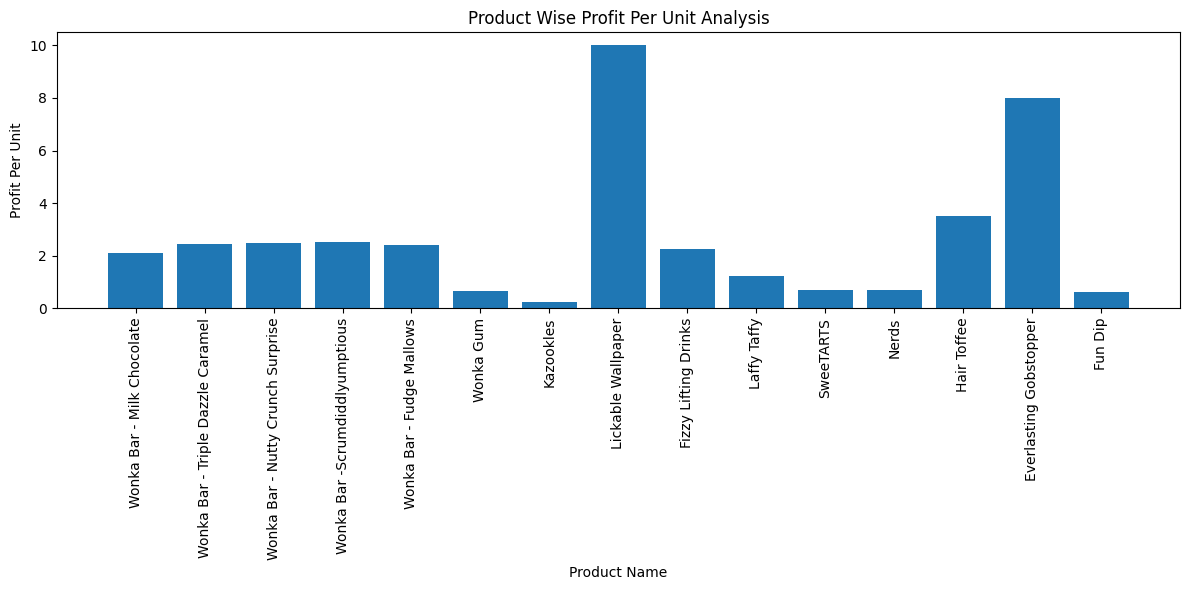

In [ ]:
plt.figure(figsize=(12,6))
plt.bar(data['Product Name'],data['Profit_per_unit'])
plt.xlabel('Product Name')
plt.ylabel('Profit Per Unit')
plt.title('Product Wise Profit Per Unit Analysis')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
#Revenue Contribution
total_sales=data['Sales'].sum()
data['Revenue_Contribution']=(data['Sales']/total_sales)*100
print(data[['Product Name','Sales','Revenue_Contribution']])


                            Product Name  Sales  Revenue_Contribution
0             Wonka Bar - Milk Chocolate   6.50              0.004584
1      Wonka Bar - Triple Dazzle Caramel   7.50              0.005290
2      Wonka Bar - Nutty Crunch Surprise  10.47              0.007384
3         Wonka Bar -Scrumdiddlyumptious  10.80              0.007617
4      Wonka Bar - Triple Dazzle Caramel  11.25              0.007935
...                                  ...    ...                   ...
10189         Wonka Bar - Milk Chocolate   9.75              0.006877
10190  Wonka Bar - Nutty Crunch Surprise   6.98              0.004923
10191     Wonka Bar -Scrumdiddlyumptious  10.80              0.007617
10192  Wonka Bar - Triple Dazzle Caramel  26.25              0.018514
10193     Wonka Bar -Scrumdiddlyumptious  10.80              0.007617

[10194 rows x 3 columns]


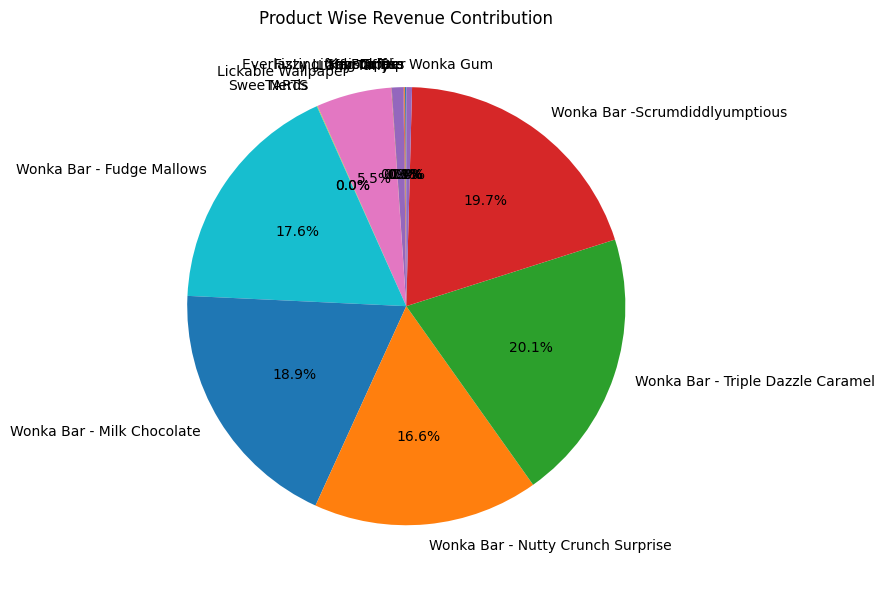

In [ ]:
import matplotlib.pyplot as plt

# 1. Aggregate revenue by Product Name first to avoid plotting 10,000+ individual transaction rows
product_revenue = data.groupby('Product Name')['Sales'].sum().reset_index()

# 2. Calculate the revenue contribution percentage for each product
total_sales = product_revenue['Sales'].sum()
product_revenue['Revenue_Contribution'] = (product_revenue['Sales'] / total_sales) * 100

# 3. Plot the aggregated product-wise revenue contribution
plt.figure(figsize=(9, 6))
plt.pie(product_revenue['Revenue_Contribution'], labels=product_revenue['Product Name'], autopct='%1.1f%%', startangle=90)
plt.title('Product Wise Revenue Contribution')
plt.tight_layout()
plt.show()

In [ ]:
#Profit Contribution
data['Gross Profit']=data['Sales']-data['Cost']
total_profit=data['Gross Profit'].sum()
data['Profit_Contribution']=(data['Gross Profit']/total_profit)*100
print(data[['Product Name','Gross Profit','Profit_Contribution']])

                            Product Name  Gross Profit  Profit_Contribution
0             Wonka Bar - Milk Chocolate          4.22             0.004516
1      Wonka Bar - Triple Dazzle Caramel          4.90             0.005244
2      Wonka Bar - Nutty Crunch Surprise          7.47             0.007994
3         Wonka Bar -Scrumdiddlyumptious          7.50             0.008026
4      Wonka Bar - Triple Dazzle Caramel          7.35             0.007866
...                                  ...           ...                  ...
10189         Wonka Bar - Milk Chocolate          6.33             0.006774
10190  Wonka Bar - Nutty Crunch Surprise          4.98             0.005329
10191     Wonka Bar -Scrumdiddlyumptious          7.50             0.008026
10192  Wonka Bar - Triple Dazzle Caramel         17.15             0.018353
10193     Wonka Bar -Scrumdiddlyumptious          7.50             0.008026

[10194 rows x 3 columns]


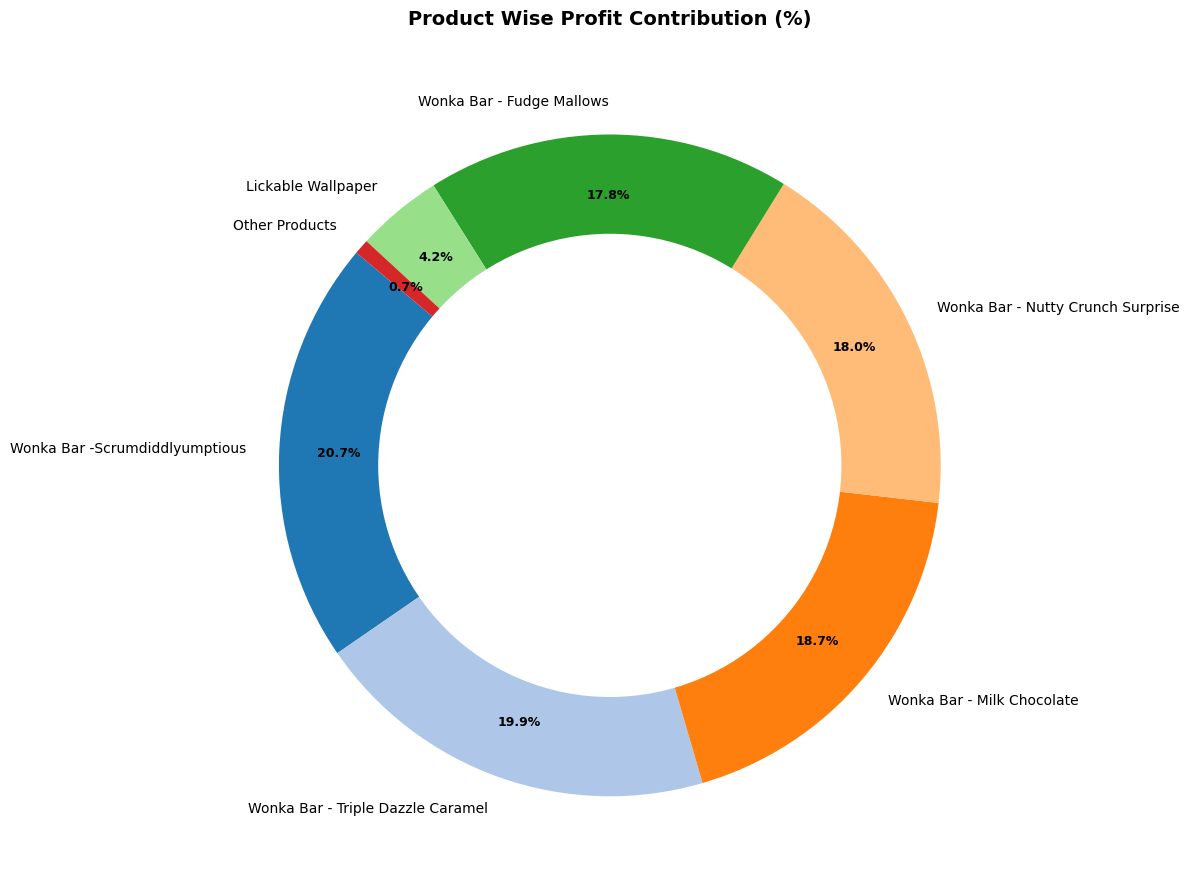

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Aggregate profit by Product Name
product_profit = data.groupby('Product Name')['Gross Profit'].sum().reset_index()

# 2. Calculate the profit contribution percentage
total_profit = product_profit['Gross Profit'].sum()
product_profit['Profit_Contribution'] = (product_profit['Gross Profit'] / total_profit) * 100
product_profit = product_profit.sort_values(by='Profit_Contribution', ascending=False).reset_index(drop=True)

# 3. Group smaller products (contrib < 1.5%) into 'Other Products' to keep the chart clean
threshold = 1.5
large_contributors = product_profit[product_profit['Profit_Contribution'] >= threshold].copy()
small_contributors = product_profit[product_profit['Profit_Contribution'] < threshold]

if not small_contributors.empty:
    other_row = {
        'Product Name': 'Other Products',
        'Gross Profit': small_contributors['Gross Profit'].sum(),
        'Profit_Contribution': small_contributors['Profit_Contribution'].sum()
    }
    chart_data = pd.concat([large_contributors, pd.DataFrame([other_row])], ignore_index=True)
else:
    chart_data = product_profit

# 4. Generate a clean, highly readable pie chart
plt.figure(figsize=(12, 9))
colors = plt.get_cmap('tab20')(np.arange(len(chart_data)))

wedges, texts, autotexts = plt.pie(
    chart_data['Profit_Contribution'],
    labels=chart_data['Product Name'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.82,
    textprops=dict(color="black", size=10)
)

# Make the percent annotations easier to read
plt.setp(autotexts, size=9, weight="bold")

# Draw a white circle at the center to turn it into a modern donut chart for better label spacing
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Product Wise Profit Contribution (%)', fontsize=14, weight='bold', pad=20)
plt.tight_layout()
plt.show()

In [ ]:
#Margin Volatility
data['Order Date'] = pd.to_datetime(data['Order Date'], dayfirst=True)
#calculating gross profit
data['Gross_Margin'] = (data['Gross Profit'] / data['Sales']) * 100
#extra month
data['Month'] = (data['Order Date'].dt.to_period('M'))
#calculating monthly product margin
monthly_margin = (data.groupby(['Product Name','Month']).agg(Sales=('Sales', sum), Cost=('Cost', sum)).reset_index())
monthly_margin['Gross_Margin'] = ((monthly_margin['Sales'] - monthly_margin['Cost']) / monthly_margin['Sales']) * 100
#calculating margin volatility
margin_volatility = (monthly_margin.groupby('Product Name')['Gross_Margin'].std().reset_index(name='Margin_Volatility'))
print(margin_volatility)

                         Product Name  Margin_Volatility
0              Everlasting Gobstopper       0.000000e+00
1                Fizzy Lifting Drinks       0.000000e+00
2                             Fun Dip       0.000000e+00
3                         Hair Toffee       0.000000e+00
4                           Kazookles       0.000000e+00
5                         Laffy Taffy       0.000000e+00
6                  Lickable Wallpaper       0.000000e+00
7                               Nerds       0.000000e+00
8                           SweeTARTS       0.000000e+00
9           Wonka Bar - Fudge Mallows       5.926336e-15
10         Wonka Bar - Milk Chocolate       1.185267e-14
11  Wonka Bar - Nutty Crunch Surprise       0.000000e+00
12  Wonka Bar - Triple Dazzle Caramel       2.963168e-15
13     Wonka Bar -Scrumdiddlyumptious       5.132358e-15
14                          Wonka Gum       2.095276e-15
